# Fase 2 – Data Understanding
Esta fase segue as quatro tarefas da metodologia CRISP-DM. Em cada tarefa são aplicados os passos do processo EDA correspondentes:

| Tarefa CRISP-DM | Passos EDA |
|---|---|
| 2.1 Recolha inicial dos dados | Passos 1 e 2 – Compreender e inspecionar |
| 2.2 Descrição dos dados | Passos 4 e 6 – Explorar e visualizar |
| 2.3 Exploração dos dados | Passos 5 e 8 – Transformar e reportar |
| 2.4 Verificação da qualidade | Passos 3 e 7 – Ausentes e outliers |

Nesta fase os problemas são **identificados**; a sua correção é feita na Fase 3 – Data Preparation.

## 2.1 Recolha Inicial dos Dados (Collect Initial Data)
> **CRISP-DM:** obter os dados listados nos recursos do projeto e carregá-los na ferramenta de análise. Output: *Initial Data Collection Report*, com os datasets obtidos, a sua localização, o método de obtenção e os problemas encontrados, bem como a forma como foram resolvidos.
>
> **Passos EDA:** 1 – Compreensão do problema e dos dados; 2 – Importação e inspeção inicial.

**Contexto (do Business Understanding):** os dados provêm de uma UCIN e estão em duas tabelas ligadas pelo código de episódio. O episódio é um acontecimento clínico e não identifica o bebé. Os sinais vitais são horários e as patologias diárias.

In [2]:
# =============================================================================
# 2.1.1 Bibliotecas
# pandas: tabelas | numpy: cálculos | matplotlib/seaborn: gráficos
# os: verificar ficheiros na pasta de dados
# =============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [3]:
# =============================================================================
# 2.1.2 Localização dos dados
# Os ficheiros foram descarregados da competição Kaggle da UC e guardados na
# pasta "dados/". Lista o conteúdo da pasta e o tamanho de cada ficheiro,
# para documentar exatamente o que foi obtido.
# =============================================================================
PASTA_DADOS = "dados/"
FICH_SINAIS = "sinais_vitais_por_hora.csv"
FICH_PATOLOGIAS = "patologias_por_dia.csv"

for f in sorted(os.listdir(PASTA_DADOS)):
    tamanho_kb = os.path.getsize(os.path.join(PASTA_DADOS, f)) / 1024
    print(f"{f:45s} {tamanho_kb:8.1f} KB")

patologias_por_dia.csv                            28.1 KB
sinais_vitais_por_hora.csv                       367.2 KB


In [4]:
# =============================================================================
# 2.1.3 Inspeção do ficheiro em bruto
# Antes de usar o pandas, lê as primeiras linhas como texto. Assim confirmamos
# o separador (vírgula ou ponto e vírgula), o separador decimal e se há
# cabeçalho. Qualquer surpresa aqui é um "problema encontrado" a registar.
# =============================================================================
for fich in [FICH_SINAIS, FICH_PATOLOGIAS]:
    print(f"--- {fich} ---")
    with open(os.path.join(PASTA_DADOS, fich), encoding="utf-8", errors="replace") as f:
        for _ in range(5):
            print(f.readline().rstrip())
    print()

--- sinais_vitais_por_hora.csv ---
episodio,data,hora,sat_o2,puls_rate,perfusion
EP001,2024-01-30,9,93.5,158.63,0.99
EP001,2024-01-30,10,92.3,155.86,0.86
EP002,2024-01-30,10,94.31,133.2,0.91
EP001,2024-01-30,11,93.96,150.0,1.13

--- patologias_por_dia.csv ---
episodio,data,patologia
EP001,2024-01-30,Displasia broncopulmonar
EP001,2024-01-30,Refluxo gastroesofágico
EP003,2024-01-30,Doença das membranas hialinas
EP003,2024-01-30,Doença das membranas hialinas



In [5]:
# =============================================================================
# 2.1.4 Carregamento dos dados
# Tenta ler em UTF-8; se falhar (acentos mal codificados), usa latin-1.
# A codificação usada fica registada para o relatório de recolha.
# =============================================================================
def carregar_csv(nome):
    caminho = os.path.join(PASTA_DADOS, nome)
    try:
        df = pd.read_csv(caminho, encoding="utf-8")
        cod = "utf-8"
    except UnicodeDecodeError:
        df = pd.read_csv(caminho, encoding="latin-1")
        cod = "latin-1"
    print(f"{nome}: carregado com codificação {cod}")
    return df

df_sinais = carregar_csv(FICH_SINAIS)
df_patologias = carregar_csv(FICH_PATOLOGIAS)

sinais_vitais_por_hora.csv: carregado com codificação utf-8
patologias_por_dia.csv: carregado com codificação utf-8


In [6]:
# =============================================================================
# 2.1.5 Volumetria
# Nº de registos e campos de cada tabela. Confirma também os valores
# referidos no relatório de Business Understanding (9 857 e 696 registos).
# =============================================================================
for nome, df, esperado in [("Sinais vitais", df_sinais, 9857),
                           ("Patologias", df_patologias, 696)]:
    linhas, colunas = df.shape
    ok = "OK" if linhas == esperado else f"DIFERENTE do relatório ({esperado})"
    print(f"{nome}: {linhas} registos x {colunas} campos -> {ok}")

Sinais vitais: 9857 registos x 6 campos -> OK
Patologias: 696 registos x 3 campos -> OK


In [7]:
# =============================================================================
# 2.1.6 Campos obtidos vs. campos esperados
# Compara os nomes das colunas com o dicionário de dados. Apanha espaços
# escondidos, maiúsculas diferentes ou colunas a mais/em falta.
# =============================================================================
esperado = {
    "Sinais vitais": ["episodio", "data", "hora", "sat_o2", "puls_rate", "perfusion"],
    "Patologias": ["episodio", "data", "patologia"],
}
for nome, df in [("Sinais vitais", df_sinais), ("Patologias", df_patologias)]:
    obtidas = df.columns.tolist()
    print(f"{nome}: {obtidas}")
    print("   Em falta:", set(esperado[nome]) - set(obtidas) or "nenhuma")
    print("   A mais:  ", set(obtidas) - set(esperado[nome]) or "nenhuma")

Sinais vitais: ['episodio', 'data', 'hora', 'sat_o2', 'puls_rate', 'perfusion']
   Em falta: nenhuma
   A mais:   nenhuma
Patologias: ['episodio', 'data', 'patologia']
   Em falta: nenhuma
   A mais:   nenhuma


In [8]:
# =============================================================================
# 2.1.7 Tipos atribuídos e valores não nulos
# Esperado: hora -> int64 | sat_o2, puls_rate, perfusion -> float64
#           episodio, data, patologia -> object (texto)
# Uma coluna numérica lida como object indica valores não numéricos lá dentro
# (gralha a analisar na tarefa 2.4).
# =============================================================================
print("===== SINAIS VITAIS =====")
df_sinais.info()
print("\n===== PATOLOGIAS =====")
df_patologias.info()

===== SINAIS VITAIS =====
<class 'pandas.DataFrame'>
RangeIndex: 9857 entries, 0 to 9856
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   9857 non-null   str  
 1   data       9857 non-null   str  
 2   hora       9857 non-null   int64
 3   sat_o2     9813 non-null   str  
 4   puls_rate  9793 non-null   str  
 5   perfusion  9815 non-null   str  
dtypes: int64(1), str(5)
memory usage: 462.2 KB

===== PATOLOGIAS =====
<class 'pandas.DataFrame'>
RangeIndex: 696 entries, 0 to 695
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   696 non-null    str  
 1   data       696 non-null    str  
 2   patologia  684 non-null    str  
dtypes: str(3)
memory usage: 16.4 KB


In [9]:
# =============================================================================
# 2.1.8 Primeiras linhas e amostra aleatória
# head() mostra o início do ficheiro; sample() mostra linhas de todo o
# ficheiro, onde é mais provável aparecerem gralhas.
# random_state fixa a amostra para ser sempre a mesma.
# =============================================================================
display(df_sinais.head())
display(df_sinais.sample(8, random_state=42))
display(df_patologias.head())
display(df_patologias.sample(8, random_state=42))

,episodio,data,hora,sat_o2,puls_rate,perfusion
0,EP001,2024-01-30,9,93.5,158.63,0.99
1,EP001,2024-01-30,10,92.3,155.86,0.86
2,EP002,2024-01-30,10,94.31,133.2,0.91
3,EP001,2024-01-30,11,93.96,150.0,1.13
4,EP002,2024-01-30,11,91.19,139.79,1.55


,episodio,data,hora,sat_o2,puls_rate,perfusion
8376,EP026,2024-04-14,5,95.24,156.27,1.19
500,EP001,2024-02-04,19,92.82,162.51,1.1
8919,EP034,2024-04-16,18,98.0,145.38,1.46
872,EP001,2024-02-08,22,91.13,154.28,1.12
5414,EP022,2024-03-17,7,94.4,149.55,2.29
5558,EP025,2024-03-18,2,97.49,126.09,1.17
7185,EP026,2024-04-03,20,94.44,146.92,0.63
7048,EP026,2024-04-01,1,96.09,157.7,1.23


,episodio,data,patologia
0,EP001,2024-01-30,Displasia broncopulmonar
1,EP001,2024-01-30,Refluxo gastroesofágico
2,EP003,2024-01-30,Doença das membranas hialinas
3,EP003,2024-01-30,Doença das membranas hialinas
4,EP003,2024-01-30,Icterícia neonatal


,episodio,data,patologia
674,EP026,2024-04-19,Displasia broncopulmonar
314,EP016,2024-03-05,Doença das membranas hialinas
611,EP039,2024-04-13,Doença das membranas hialinas
431,EP027,2024-03-17,Citomegalovírus
552,EP027,2024-04-03,Citomegalovírus
211,EP015,2024-02-24,Doença das membranas hialinas
538,EP032,2024-03-30,Sépsis
176,EP001,2024-02-20,Displasia broncopulmonar


In [10]:
# =============================================================================
# 2.1.9 Ligação entre as duas fontes
# O CRISP-DM lembra que, com várias fontes, a integração é uma questão a
# considerar já aqui. Verifica se as tabelas falam dos mesmos episódios.
# (A integração propriamente dita é feita na Fase 3.)
# =============================================================================
ep_sinais = set(df_sinais["episodio"])
ep_patologias = set(df_patologias["episodio"])

print("Episódios nos sinais vitais:", len(ep_sinais))
print("Episódios nas patologias:   ", len(ep_patologias))
print("Em ambas as tabelas:        ", len(ep_sinais & ep_patologias))
print("Só nos sinais vitais:       ", len(ep_sinais - ep_patologias))
print("Só nas patologias:          ", len(ep_patologias - ep_sinais))

Episódios nos sinais vitais: 58
Episódios nas patologias:    45
Em ambas as tabelas:         40
Só nos sinais vitais:        18
Só nas patologias:           5


In [11]:
# =============================================================================
# 2.1.10 Episódios presentes só numa das tabelas
# Lista os códigos para documentar a discrepância. Se houver códigos
# parecidos (ex.: "EP01" vs "EP001", "ep001"), é gralha e não falta de dados.
# A análise completa é feita na tarefa 2.4.
# =============================================================================
print("Só nas patologias:   ", sorted(ep_patologias - ep_sinais))
print("Só nos sinais vitais:", sorted(ep_sinais - ep_patologias))

Só nas patologias:    [' EP009', ' EP020', 'EP 018', 'EP 037', 'ep029']
Só nos sinais vitais: [' EP011', ' EP016', ' EP027', 'EP 016', 'EP 026', 'EP 034', 'EP 036', 'EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047', 'ep016', 'ep019', 'ep023']


### Relatório de Recolha Inicial dos Dados

**Datasets obtidos**

| Dataset | Localização | Método de obtenção | Registos x campos | Formato |
|---|---|---|---|---|
| sinais_vitais_por_hora.csv | dados/ | Download da competição Kaggle da UC | 9 857 x 6 | CSV, separador vírgula, ponto decimal, UTF-8 |
| patologias_por_dia.csv | dados/ | Download da competição Kaggle da UC | 696 x 3 | CSV, separador vírgula, ponto decimal, UTF-8 |

Os dois ficheiros foram carregados em Python (pandas) sem erros de leitura. O número de registos coincide com o indicado no Business Understanding e todos os campos do dicionário de dados estão presentes, sem colunas adicionais. Não existem outras fontes de dados para o projeto.

**Problemas encontrados**

| Problema | Onde | Detalhe | Resolução |
|---|---|---|---|
| Colunas numéricas lidas como texto | sat_o2, puls_rate, perfusion | Existem valores não numéricos nestas colunas | Identificar os valores na tarefa 2.4; converter para número na Fase 3 |
| Valores em falta | sat_o2 (44), puls_rate (64), perfusion (42), patologia (12) | Representados como células vazias | Caracterizar na tarefa 2.4; definir tratamento na Fase 3 |
| Códigos de episódio inconsistentes | Ambas as tabelas | Espaço no início (" EP009"), espaço no meio ("EP 018") e minúsculas ("ep029") | Normalizar os códigos (remover espaços e converter para maiúsculas) na Fase 3 |

**Correspondência entre tabelas**

Sem normalização, os sinais vitais têm 58 códigos de episódio e as patologias 45, com 40 em comum. A maior parte da diferença deve-se às gralhas nos códigos, que fazem o mesmo episódio aparecer com vários códigos. Depois de normalizados, os episódios só com patologias deverão desaparecer. Ficam apenas com sinais vitais, e sem patologias registadas, oito episódios: EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047. Estes números serão confirmados na tarefa 2.4.

**Nota sobre integração:** as duas fontes ligam-se pelos campos `episodio` e `data`, mas têm granularidades diferentes (sinais vitais por hora e patologias por dia). A integração será feita na Fase 3, depois de corrigidos os códigos de episódio e os restantes problemas de qualidade.

## 2.2 Descrição dos Dados (Describe Data)
> **CRISP-DM:** examinar as propriedades "de superfície" dos dados obtidos: formato, quantidade (registos e campos de cada tabela), identidade dos campos e outras características gerais. Avaliar se os dados satisfazem os requisitos do projeto. Output: *Data Description Report*.
>
> **Passos EDA:** 4 – Medidas de tendência central e dispersão; 6 – Visualização (análise univariada).

**Nota:** para calcular estatísticas é criada uma cópia de trabalho de cada tabela, com os valores numéricos convertidos e os códigos de episódio normalizados. Os valores que não é possível converter são excluídos das estatísticas e analisados na tarefa 2.4. Os dados originais não são alterados.

### 2.2.1 Identidade dos campos

| Tabela | Campo | Descrição | Tipo | Unidade / domínio |
|---|---|---|---|---|
| Sinais vitais | episodio | Código do episódio clínico | Qualitativo nominal (identificador) | EPxxx |
| Sinais vitais | data | Dia do registo | Data | AAAA-MM-DD |
| Sinais vitais | hora | Hora do dia (9 = 09:00–09:59) | Quantitativo discreto (cíclico) | 0–23 |
| Sinais vitais | sat_o2 | Saturação periférica de oxigénio, valor típico da hora | Quantitativo contínuo | %, 0–100 |
| Sinais vitais | puls_rate | Frequência de pulso, valor típico da hora | Quantitativo contínuo | bpm |
| Sinais vitais | perfusion | Índice de perfusão, valor típico da hora | Quantitativo contínuo | % |
| Patologias | episodio | Código do episódio clínico | Qualitativo nominal (identificador) | EPxxx |
| Patologias | data | Dia do registo | Data | AAAA-MM-DD |
| Patologias | patologia | Patologia confirmada no registo clínico | Qualitativo nominal | 13 valores possíveis |

In [12]:
# =============================================================================
# 2.2.2 Cópias de trabalho para a descrição
# - episodio: remove espaços e passa a maiúsculas (" ep 016" -> "EP016")
# - data: converte para datas; datas inválidas ficam vazias (NaT)
# - sinais vitais: converte para número; texto inválido fica vazio (NaN)
# - patologia: remove espaços nas pontas e uniformiza maiúsculas
# Conta quantos valores existiam mas não foi possível converter.
# Os DataFrames originais (df_sinais, df_patologias) ficam intactos.
# =============================================================================
sv = df_sinais.copy()
pat = df_patologias.copy()

for df in (sv, pat):
    df["episodio"] = df["episodio"].str.replace(" ", "", regex=False).str.upper()
    df["data_dt"] = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")

VITAIS = ["sat_o2", "puls_rate", "perfusion"]
for col in VITAIS:
    convertido = pd.to_numeric(sv[col], errors="coerce")
    falhas = (convertido.isna() & sv[col].notna()).sum()
    print(f"{col}: {falhas} valores não convertíveis para número")
    sv[col] = convertido

pat["patologia"] = pat["patologia"].str.strip().str.capitalize()

print("\nDatas inválidas -> sinais:", sv["data_dt"].isna().sum(),
      "| patologias:", pat["data_dt"].isna().sum())

sat_o2: 3 valores não convertíveis para número
puls_rate: 7 valores não convertíveis para número
perfusion: 5 valores não convertíveis para número

Datas inválidas -> sinais: 18 | patologias: 10


In [13]:
# =============================================================================
# 2.2.3 Quantidade de dados
# Nº de episódios (com códigos normalizados), período coberto e quanto tempo
# cada episódio está registado (dias e horas). A duração por episódio é a
# base da futura variável "duração do internamento" (objetivo DM2).
# =============================================================================
print("Episódios (normalizados) -> sinais:", sv["episodio"].nunique(),
      "| patologias:", pat["episodio"].nunique(),
      "| total:", len(set(sv["episodio"]) | set(pat["episodio"])))
print("Período dos sinais vitais:", sv["data_dt"].min().date(), "->", sv["data_dt"].max().date())
print("Período das patologias:   ", pat["data_dt"].min().date(), "->", pat["data_dt"].max().date())

por_episodio = sv.groupby("episodio").agg(
    registos=("hora", "size"),
    dias_distintos=("data_dt", "nunique"),
    primeiro_dia=("data_dt", "min"),
    ultimo_dia=("data_dt", "max"),
)
por_episodio["duracao_dias"] = (por_episodio["ultimo_dia"] - por_episodio["primeiro_dia"]).dt.days + 1

print("\nResumo por episódio (sinais vitais):")
display(por_episodio[["registos", "dias_distintos", "duracao_dias"]].describe().round(1))

Episódios (normalizados) -> sinais: 47 | patologias: 39 | total: 47
Período dos sinais vitais: 2024-01-30 -> 2024-04-20
Período das patologias:    2024-01-30 -> 2024-04-20

Resumo por episódio (sinais vitais):


,registos,dias_distintos,duracao_dias
count,47.0,47.0,47.0
mean,209.7,9.6,9.7
std,198.4,8.2,8.3
min,4.0,1.0,1.0
25%,62.5,3.5,3.5
50%,143.0,7.0,7.0
75%,301.5,13.5,13.5
max,853.0,36.0,36.0


In [14]:
# =============================================================================
# 2.2.4 Medidas de tendência central e dispersão (Passo 4)
# Para cada sinal vital: média, mediana, moda, desvio padrão, mínimo, máximo,
# quartis, coeficiente de variação, assimetria e curtose.
# - Assimetria ~0: simétrica | >0: cauda à direita | <0: cauda à esquerda
# - Média muito diferente da mediana sugere outliers ou distribuição enviesada
# =============================================================================
estat = sv[VITAIS].describe().T
estat["mediana"] = sv[VITAIS].median()
estat["moda"] = sv[VITAIS].mode().iloc[0]
estat["cv_%"] = estat["std"] / estat["mean"] * 100
estat["assimetria"] = sv[VITAIS].skew()
estat["curtose"] = sv[VITAIS].kurt()
display(estat[["count", "mean", "mediana", "moda", "std", "cv_%", "min", "25%", "75%", "max",
               "assimetria", "curtose"]].round(2))

,count,mean,mediana,moda,std,cv_%,min,25%,75%,max,assimetria,curtose
sat_o2,9810.0,96.25,96.27,96.98,14.05,14.59,-5.0,94.67,97.63,999.0,55.01,3492.09
puls_rate,9786.0,148.11,149.38,157.96,24.13,16.29,-10.0,138.96,158.17,999.0,19.01,652.05
perfusion,9810.0,1.30,1.15,1.06,2.52,193.66,-1.0,0.91,1.44,99.0,33.21,1216.25


In [15]:
# =============================================================================
# 2.2.5 Campo hora
# Confirma que só existem valores de 0 a 23 e quantos registos há por hora.
# Uma distribuição muito irregular indica horas em falta nas séries.
# =============================================================================
print("Valores distintos de hora:", sorted(sv["hora"].unique()))
display(sv["hora"].value_counts().sort_index().to_frame("registos").T)

Valores distintos de hora: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]


hora,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
registos,5,401,404,413,411,413,413,416,413,417,416,417,420,407,407,408,405,410,406,407,407,408,410,411,409,2,1


In [16]:
# =============================================================================
# 2.2.6 Campo patologia
# Nº de valores distintos (deviam ser no máximo 13), frequência de cada um e
# nº de patologias registadas por episódio e dia (multi-label).
# Variantes mal escritas que persistam aparecem aqui como valores a mais.
# =============================================================================
print("Valores distintos:", pat["patologia"].nunique(), "| em falta:", pat["patologia"].isna().sum())
display(pat["patologia"].value_counts(dropna=False).to_frame("registos"))

por_dia = pat.groupby(["episodio", "data_dt"])["patologia"].nunique()
print("Patologias distintas por episódio e dia:")
display(por_dia.value_counts().sort_index().to_frame("nº de episódio-dia"))

Valores distintos: 18 | em falta: 12


,registos
patologia,
Doença das membranas hialinas,271
Icterícia neonatal,162
Anemia,56
Citomegalovírus,49
Displasia broncopulmonar,38
Persistência do canal arterial,32
Refluxo gastroesofágico,26
Sépsis,18
NaN,12


Patologias distintas por episódio e dia:


,nº de episódio-dia
patologia,
0,4
1,266
2,139
3,33
4,4


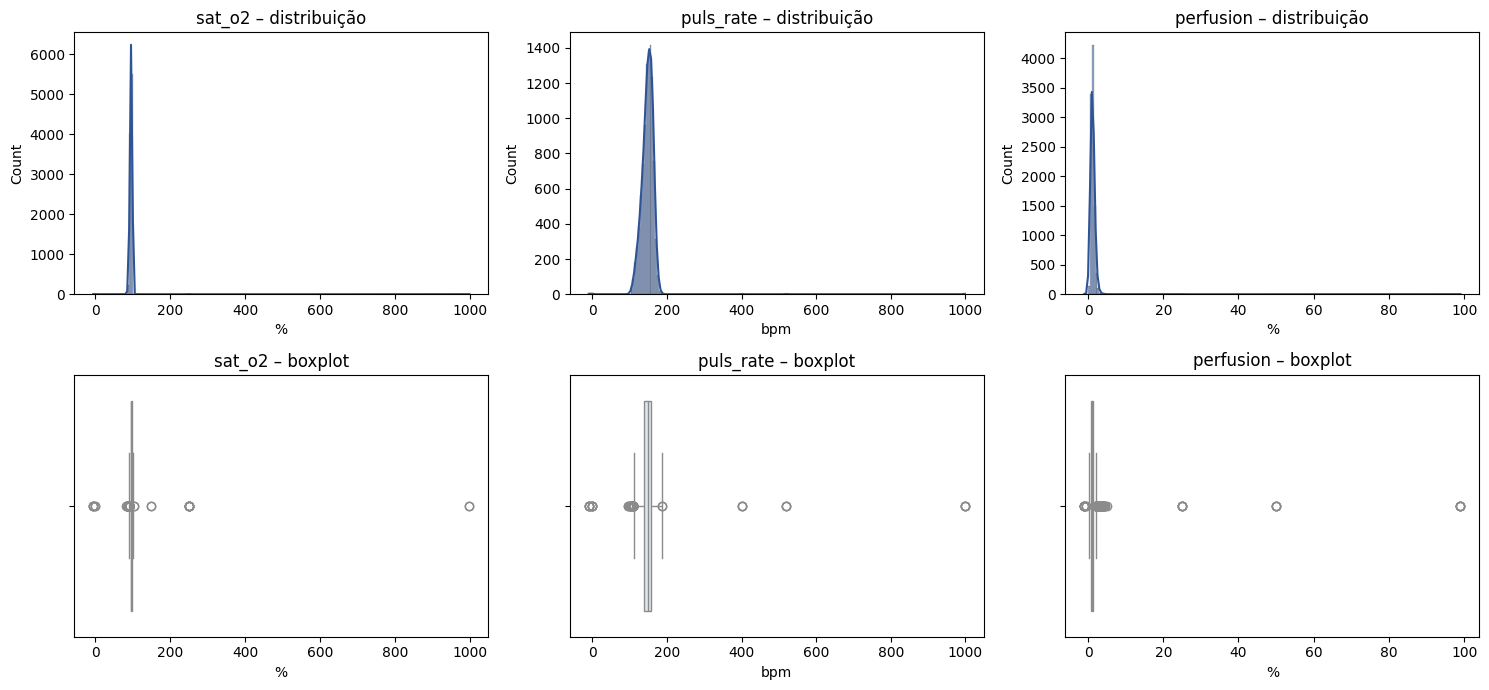

In [17]:
# =============================================================================
# 2.2.7 Visualização univariada dos sinais vitais (Passo 6)
# Histograma com curva de densidade (forma da distribuição) e boxplot
# (mediana, dispersão e possíveis outliers) para cada sinal vital.
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
unidades = {"sat_o2": "%", "puls_rate": "bpm", "perfusion": "%"}

for i, col in enumerate(VITAIS):
    sns.histplot(sv[col].dropna(), kde=True, ax=axes[0, i], color="#2F5496")
    axes[0, i].set_title(f"{col} – distribuição")
    axes[0, i].set_xlabel(unidades[col])
    sns.boxplot(x=sv[col].dropna(), ax=axes[1, i], color="#DCE6F2")
    axes[1, i].set_title(f"{col} – boxplot")
    axes[1, i].set_xlabel(unidades[col])

plt.tight_layout()
plt.show()

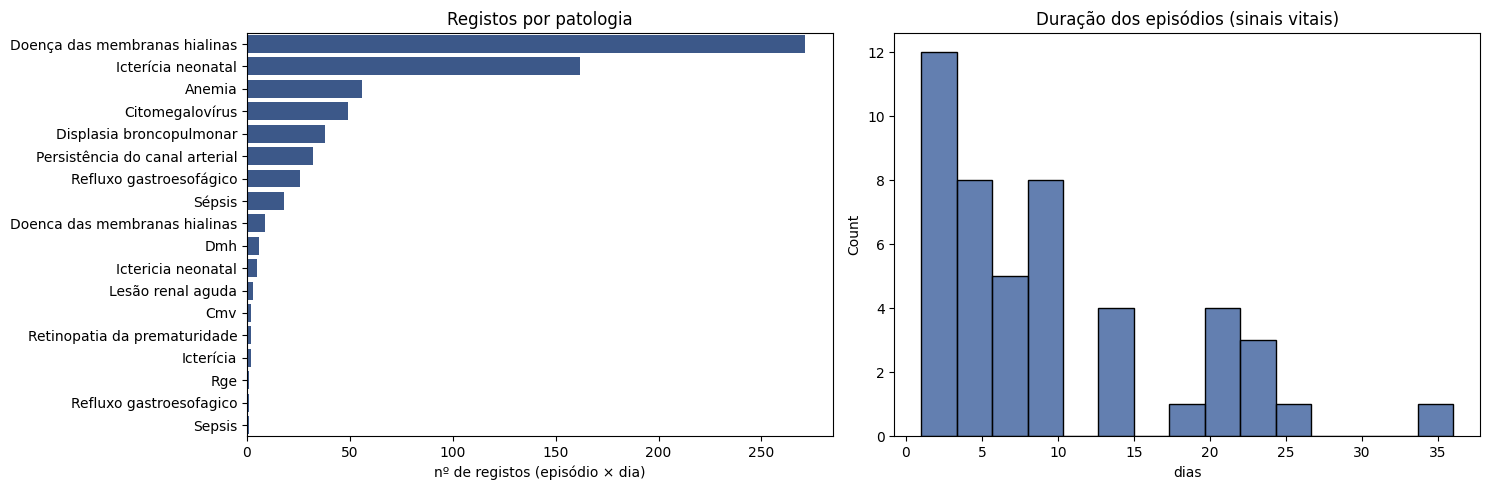

In [18]:
# =============================================================================
# 2.2.8 Visualização das patologias e da duração dos episódios (Passo 6)
# Esquerda: nº de registos por patologia (mostra o desequilíbrio entre classes)
# Direita: duração de cada episódio em dias (base da variável alvo da regressão)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

freq = pat["patologia"].value_counts()
sns.barplot(x=freq.values, y=freq.index, ax=axes[0], color="#2F5496")
axes[0].set_title("Registos por patologia")
axes[0].set_xlabel("nº de registos (episódio × dia)")
axes[0].set_ylabel("")

sns.histplot(por_episodio["duracao_dias"], bins=15, ax=axes[1], color="#2F5496")
axes[1].set_title("Duração dos episódios (sinais vitais)")
axes[1].set_xlabel("dias")

plt.tight_layout()
plt.show()

sat_o2: 27 valores fora de [50, 100]
puls_rate: 20 valores fora de [50, 250]
perfusion: 23 valores fora de [0, 20]


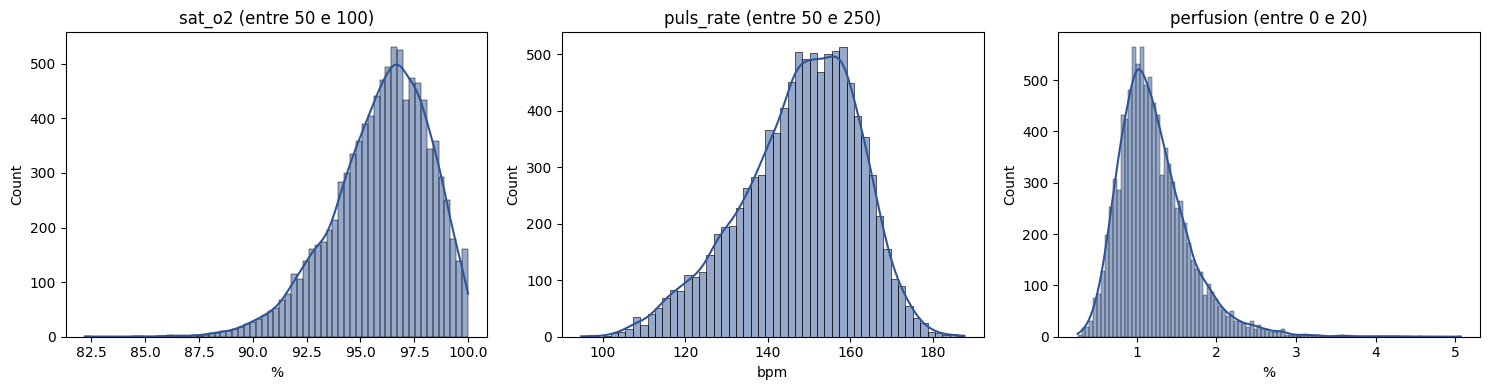

In [19]:
# =============================================================================
# 2.2.9 Distribuições dentro de limites fisiologicamente plausíveis (Passo 6)
# Os valores impossíveis (ex.: 999) achatam os gráficos anteriores.
# Aqui mostram-se só os valores dentro de limites plausíveis, para ver a forma
# real das distribuições. Os valores fora dos limites são contados e
# analisados na tarefa 2.4 (não são removidos).
# =============================================================================
LIMITES = {"sat_o2": (50, 100), "puls_rate": (50, 250), "perfusion": (0, 20)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(VITAIS):
    lo, hi = LIMITES[col]
    dentro = sv[col].between(lo, hi)
    fora = sv[col].notna() & ~dentro
    print(f"{col}: {fora.sum()} valores fora de [{lo}, {hi}]")
    sns.histplot(sv.loc[dentro, col], kde=True, ax=axes[i], color="#2F5496")
    axes[i].set_title(f"{col} (entre {lo} e {hi})")
    axes[i].set_xlabel(unidades[col])

plt.tight_layout()
plt.show()

### Relatório de Descrição dos Dados

**Formato e quantidade**

| Tabela | Registos | Campos | Episódios (códigos normalizados) | Período |
|---|---|---|---|---|
| Sinais vitais | 9 857 | 6 | 47 | 30/01/2024 a 20/04/2024 |
| Patologias | 696 | 3 | 39 | 30/01/2024 a 20/04/2024 |

Depois de normalizados os códigos de episódio, existem **47 episódios**. Todos os episódios com patologias têm também sinais vitais e **8 episódios não têm qualquer patologia registada** (EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047).

**Episódios**

Cada episódio tem, em mediana, 143 registos horários ao longo de 7 dias (mínimo 1 dia, máximo 36). O número de dias distintos com registos é praticamente igual à duração entre o primeiro e o último dia, o que indica uma monitorização contínua. A distribuição da duração tem cauda à direita: 12 episódios duram 3 dias ou menos e poucos ultrapassam 20 dias.

**Sinais vitais**

| Variável | Mediana | Q1 – Q3 | Mínimo | Máximo | Observação |
|---|---|---|---|---|---|
| sat_o2 (%) | 96,27 | 94,67 – 97,63 | −5 | 999 | Valores impossíveis (< 0 e > 100) |
| puls_rate (bpm) | 149,38 | 138,96 – 158,17 | −10 | 999 | Valores impossíveis (≤ 0, 400, 520, 999) |
| perfusion (%) | 1,15 | 0,91 – 1,44 | −1 | 99 | Valores suspeitos (< 0, 25, 50, 99) |

As medianas e os quartis são clinicamente plausíveis para recém-nascidos internados. Um pequeno número de valores impossíveis, possivelmente códigos de "valor desconhecido" como 999 e 99, distorce a média, o desvio padrão e a assimetria. Por isso, a mediana e os quartis são as medidas mais fiáveis nesta fase. Não foi possível converter para número 3 valores de sat_o2, 7 de puls_rate e 5 de perfusion.

Excluindo os valores impossíveis, as distribuições são clinicamente plausíveis. A sat_o2 concentra-se entre 92 % e 100 %, com pico perto de 97 %, cauda à esquerda e limite natural em 100 %. A puls_rate varia entre cerca de 100 e 185 bpm, com pico entre 145 e 160 bpm e ligeira assimetria à esquerda. A perfusion varia entre cerca de 0,3 % e 5 %, com pico em 1 % e cauda à direita.

**Hora**

Os registos distribuem-se de forma uniforme pelas 24 horas (401 a 420 por hora). Existem valores fora do domínio: −1 (5 registos), 24 (2) e 25 (1).

**Patologias**

Há 18 designações distintas, quando o domínio tem 13. As diferenças devem-se a nomes sem acentos ("Doenca das membranas hialinas", "Sepsis"), siglas ("Dmh", "Cmv", "Rge") e nomes incompletos ("Icterícia"). Agrupando as variantes, só 10 das 13 patologias aparecem nos dados. Hemorragia peri-intraventricular, enterocolite necrosante e doença metabólica óssea da prematuridade não têm registos. Existem 12 registos sem patologia.

As classes estão muito desequilibradas: a doença das membranas hialinas representa cerca de 42 % dos registos e a icterícia neonatal 25 %, enquanto a lesão renal aguda e a retinopatia da prematuridade têm 3 e 2 registos.

Dos 446 pares episódio-dia, cerca de 39 % têm duas ou mais patologias, o que confirma o carácter multi-label do problema (valor a confirmar após a correção das designações, já que variantes do mesmo nome são contadas como patologias distintas).

**Datas**

Existem 18 datas inválidas nos sinais vitais e 10 nas patologias, analisadas na tarefa 2.4.

**Níveis de análise**

As patologias são registadas por dia e variam ao longo do episódio, tal como os sinais vitais. Por isso, a classificação de patologias será feita ao nível do par episódio-dia (cerca de 446 exemplos). A duração do internamento e o clustering são características do episódio inteiro e serão analisados ao nível do episódio (47 exemplos).

**Os dados satisfazem os requisitos do projeto?**

| Objetivo | Avaliação |
|---|---|
| DM1 – Classificação | **Parcialmente.** Há cerca de 446 pares episódio-dia com patologias, mas só 10 das 13 patologias existem e algumas têm 2 ou 3 registos. Será necessário trabalhar apenas com as patologias mais frequentes ou agrupá-las. |
| DM2 – Regressão | **Com limitações.** A duração do internamento pode ser construída a partir das datas, mas, se for calculada por episódio, só há 47 exemplos. Alternativas a analisar na tarefa 2.3. |
| DM3 – Clustering | **Sim**, com 47 episódios caracterizados pelos sinais vitais e pelas patologias, embora seja uma amostra pequena. |
| Qualidade | Os problemas encontrados (códigos, nomes, valores impossíveis, datas e horas inválidas) são corrigíveis e serão detalhados na tarefa 2.4. |

## 2.3 Exploração dos Dados (Explore Data)
> **CRISP-DM:** responder a questões de data mining através de consultas, visualizações e relatórios: distribuição dos atributos-chave (incluindo a variável alvo), relações entre pares de atributos, agregações simples, propriedades de subpopulações e análises estatísticas simples. Output: *Data Exploration Report*, com os primeiros resultados, as hipóteses iniciais e o seu impacto no resto do projeto.
>
> **Passos EDA:** 5 – Transformação dos dados (para explorar); 8 – Reportar.

A exploração é orientada pelos objetivos de data mining:
- **DM1 – Classificação** ao nível do episódio-dia
- **DM2 – Regressão** ao nível do episódio
- **DM3 – Clustering** ao nível do episódio

**Nota:** a exploração usa cópias em que os valores impossíveis, as datas e horas inválidas e os registos repetidos são excluídos, e as variantes dos nomes de patologia são agrupadas. A correção definitiva é feita na Fase 3.

In [20]:
# =============================================================================
# 2.3.1 Cópias exploratórias
# Partem das cópias de trabalho da 2.2 (sv, pat) e excluem, só para explorar:
# - datas inválidas e horas fora de 0-23
# - sinais vitais fora dos limites plausíveis (ficam vazios, não se apaga a linha)
# - patologias em falta e registos repetidos
# As variantes dos nomes de patologia são agrupadas no nome oficial.
# A correção definitiva destes problemas é feita na Fase 3.
# =============================================================================
MAPA_PATOLOGIAS = {
    "Doenca das membranas hialinas": "Doença das membranas hialinas",
    "Dmh": "Doença das membranas hialinas",
    "Ictericia neonatal": "Icterícia neonatal",
    "Icterícia": "Icterícia neonatal",
    "Cmv": "Citomegalovírus",
    "Rge": "Refluxo gastroesofágico",
    "Refluxo gastroesofagico": "Refluxo gastroesofágico",
    "Sepsis": "Sépsis",
}

sv_exp = sv[sv["data_dt"].notna() & sv["hora"].between(0, 23)].copy()
for col in VITAIS:
    lo, hi = LIMITES[col]
    sv_exp.loc[~sv_exp[col].between(lo, hi), col] = np.nan

pat_exp = pat[pat["data_dt"].notna() & pat["patologia"].notna()].copy()
pat_exp["patologia"] = pat_exp["patologia"].replace(MAPA_PATOLOGIAS)
pat_exp = pat_exp.drop_duplicates(subset=["episodio", "data_dt", "patologia"])

print(f"Sinais vitais: {len(sv)} -> {len(sv_exp)} registos")
print(f"Patologias:    {len(pat)} -> {len(pat_exp)} registos")
print("Patologias distintas após agrupar variantes:", pat_exp["patologia"].nunique())

Sinais vitais: 9857 -> 9831 registos
Patologias:    696 -> 659 registos
Patologias distintas após agrupar variantes: 10


In [21]:
# =============================================================================
# 2.3.2 Tabela episódio-dia (Passo 5 – Transformar)
# Uma linha por episódio e dia, com:
# - sinais vitais agregados no dia: média, mínimo, máximo e desvio padrão
# - uma coluna 0/1 por patologia (1 = registada nesse dia)
# - n_patologias: nº de patologias registadas nesse dia
# É a granularidade do objetivo DM1 (classificação).
# =============================================================================
vit_dia = sv_exp.groupby(["episodio", "data_dt"])[VITAIS].agg(["mean", "min", "max", "std"])
vit_dia.columns = [f"{v}_{f}" for v, f in vit_dia.columns]
vit_dia["n_horas"] = sv_exp.groupby(["episodio", "data_dt"]).size()

pat_dia = pd.crosstab([pat_exp["episodio"], pat_exp["data_dt"]], pat_exp["patologia"]).clip(upper=1)
PATOLOGIAS = pat_dia.columns.tolist()

ep_dia = vit_dia.join(pat_dia, how="left")
ep_dia[PATOLOGIAS] = ep_dia[PATOLOGIAS].fillna(0).astype(int)
ep_dia["n_patologias"] = ep_dia[PATOLOGIAS].sum(axis=1)
ep_dia = ep_dia.reset_index()

print("Tabela episódio-dia:", ep_dia.shape)
display(ep_dia.head())

Tabela episódio-dia: (449, 26)


,episodio,data_dt,sat_o2_mean,sat_o2_min,sat_o2_max,sat_o2_std,puls_rate_mean,puls_rate_min,puls_rate_max,puls_rate_std,perfusion_mean,perfusion_min,perfusion_max,perfusion_std,n_horas,Anemia,Citomegalovírus,Displasia broncopulmonar,Doença das membranas hialinas,Icterícia neonatal,Lesão renal aguda,Persistência do canal arterial,Refluxo gastroesofágico,Retinopatia da prematuridade,Sépsis,n_patologias
0,EP001,2024-01-30,92.949333,90.00,95.49,1.808122,156.748000,148.50,168.32,5.541287,1.083333,0.49,1.64,0.305933,15,0,0,1,0,0,0,0,1,0,0,2
1,EP001,2024-01-31,94.213333,90.42,99.79,2.177074,160.556250,147.06,169.00,4.973546,0.962917,0.59,1.49,0.238555,24,0,0,1,0,0,0,0,1,0,0,2
2,EP001,2024-02-01,94.175833,90.00,98.45,2.075222,161.395417,149.87,174.56,6.104747,1.149167,0.78,1.66,0.257123,24,0,0,1,0,0,0,0,1,0,0,2
3,EP001,2024-02-02,94.679583,91.39,97.08,1.497849,162.422917,149.02,175.15,7.018494,1.188750,0.58,1.57,0.246459,24,0,0,1,0,0,0,0,1,0,0,2
4,EP001,2024-02-03,94.687083,91.67,97.31,1.468802,160.155000,149.96,175.16,6.123598,1.147500,0.81,1.53,0.190086,24,0,0,1,0,0,0,0,1,0,0,2


In [27]:
# =============================================================================
# 2.3.3 Tabela episódio (Passo 5 – Transformar)
# Uma linha por episódio, para os objetivos DM2 (regressão) e DM3 (clustering):
# - inicio / fim: período com sinais vitais (monitorização)
# - sinais vitais: mediana das médias diárias
# - duracao_monitor: duração só com os sinais vitais
# - duracao_total: duração com AMBAS as tabelas (do primeiro ao último
#   registo em qualquer uma) -> candidata a variável alvo da regressão
# - patologias: 1 se a patologia foi registada em algum dia do episódio,
#   incluindo dias sem sinais vitais
# - cortado: episódio que começa no primeiro ou acaba no último dia dos dados
#   (a duração real pode ser maior do que a medida)
# =============================================================================
DIA_INICIO, DIA_FIM = sv_exp["data_dt"].min(), sv_exp["data_dt"].max()

ep = ep_dia.groupby("episodio").agg(
    inicio=("data_dt", "min"), fim=("data_dt", "max"), dias=("data_dt", "nunique"),
    sat_o2=("sat_o2_mean", "median"), puls_rate=("puls_rate_mean", "median"),
    perfusion=("perfusion_mean", "median"),
)
ep["duracao_monitor"] = (ep["fim"] - ep["inicio"]).dt.days + 1

# Duração com as duas tabelas
datas_todas = pd.concat([sv_exp[["episodio", "data_dt"]], pat_exp[["episodio", "data_dt"]]])
limites = datas_todas.groupby("episodio")["data_dt"].agg(["min", "max"])
ep["inicio_total"] = limites["min"]
ep["fim_total"] = limites["max"]
ep["duracao_total"] = (ep["fim_total"] - ep["inicio_total"]).dt.days + 1

# Patologias a partir de todos os registos (com ou sem sinais vitais nesse dia)
ep[PATOLOGIAS] = (pd.crosstab(pat_exp["episodio"], pat_exp["patologia"]).clip(upper=1)
                  .reindex(index=ep.index, columns=PATOLOGIAS, fill_value=0))
ep["n_patologias_distintas"] = ep[PATOLOGIAS].sum(axis=1)

ep["cortado"] = (ep["inicio_total"] == DIA_INICIO) | (ep["fim_total"] == DIA_FIM)

print("Tabela episódio:", ep.shape)
print("Episódios cortados pelo período de recolha:", ep["cortado"].sum())
display(ep.head())

Tabela episódio: (47, 22)
Episódios cortados pelo período de recolha: 14


,inicio,fim,dias,sat_o2,puls_rate,perfusion,duracao_monitor,inicio_total,fim_total,duracao_total,Anemia,Citomegalovírus,Displasia broncopulmonar,Doença das membranas hialinas,Icterícia neonatal,Lesão renal aguda,Persistência do canal arterial,Refluxo gastroesofágico,Retinopatia da prematuridade,Sépsis,n_patologias_distintas,cortado
episodio,,,,,,,,,,,,,,,,,,,,,,
EP001,2024-01-30,2024-02-22,24,94.141625,159.232464,1.152525,24,2024-01-30,2024-02-26,28,1,0,1,0,0,0,0,1,1,0,4,True
EP002,2024-01-30,2024-02-01,3,95.113043,141.054348,1.337391,3,2024-01-30,2024-02-06,8,0,1,0,0,0,0,0,0,0,0,1,True
EP003,2024-01-30,2024-02-04,6,97.530108,162.911667,1.118125,6,2024-01-30,2024-02-12,14,0,0,0,1,1,0,0,0,0,0,2,True
EP004,2024-02-02,2024-02-27,23,97.862083,149.417500,1.546667,26,2024-02-02,2024-02-27,26,0,1,0,1,1,1,1,0,0,0,5,False
EP005,2024-02-03,2024-02-06,4,98.267583,126.633614,0.984547,4,2024-02-03,2024-02-07,5,0,0,0,0,1,0,0,0,0,0,1,False


In [28]:
# =============================================================================
# 2.3.4 Multi-label após agrupar as variantes dos nomes
# Recalcula quantas patologias tem cada episódio-dia, agora com os nomes
# corrigidos (confirma o valor de ~39% visto na 2.2).
# Inclui os dias sem patologia registada (n = 0).
# =============================================================================
dist = ep_dia["n_patologias"].value_counts().sort_index()
display(dist.to_frame("nº de episódio-dia"))
com_pat = ep_dia[ep_dia["n_patologias"] > 0]
print(f"Dias com pelo menos uma patologia: {len(com_pat)} de {len(ep_dia)}")
print(f"Desses, com 2 ou mais: {(com_pat['n_patologias'] >= 2).mean():.1%}")

,nº de episódio-dia
n_patologias,
0,110
1,188
2,119
3,30
4,2


Dias com pelo menos uma patologia: 339 de 449
Desses, com 2 ou mais: 44.5%


In [31]:
# =============================================================================
# 2.3.4b Dias com patologia sem sinais vitais
# A tabela episódio-dia (2.3.2) parte dos sinais vitais, por isso os dias
# com patologia mas sem nenhum sinal vital ficam de fora. Esta célula conta
# esses dias e classifica-os em relação ao período com monitorização de cada
# episódio: antes do início, depois do fim ou a meio (interrupções).
# =============================================================================
dias_pat = pat_exp[["episodio", "data_dt"]].drop_duplicates()
dias_sv = ep_dia[["episodio", "data_dt"]]

so_pat = dias_pat.merge(dias_sv, how="left", indicator=True)
so_pat = so_pat[so_pat["_merge"] == "left_only"].drop(columns="_merge")
print(f"Dias com patologia: {len(dias_pat)} | sem sinais vitais nesse dia: {len(so_pat)}")

# Posição em relação ao período com sinais vitais de cada episódio
so_pat = so_pat.merge(ep[["inicio", "fim"]], left_on="episodio", right_index=True, how="left")
so_pat["posicao"] = np.select(
    [so_pat["data_dt"] < so_pat["inicio"], so_pat["data_dt"] > so_pat["fim"]],
    ["antes do início", "depois do fim"], default="a meio do episódio")
display(so_pat["posicao"].value_counts().to_frame("nº de dias"))
display(so_pat.head(10))

Dias com patologia: 442 | sem sinais vitais nesse dia: 103


,nº de dias
posicao,
depois do fim,92
a meio do episódio,6
antes do início,5


,episodio,data_dt,inicio,fim,posicao
8,EP002,2024-02-02,2024-01-30,2024-02-01,depois do fim
11,EP002,2024-02-03,2024-01-30,2024-02-01,depois do fim
17,EP004,2024-02-04,2024-02-02,2024-02-27,a meio do episódio
22,EP002,2024-02-05,2024-01-30,2024-02-01,depois do fim
23,EP003,2024-02-05,2024-01-30,2024-02-04,depois do fim
24,EP004,2024-02-05,2024-02-02,2024-02-27,a meio do episódio
29,EP002,2024-02-06,2024-01-30,2024-02-01,depois do fim
30,EP003,2024-02-06,2024-01-30,2024-02-04,depois do fim
31,EP004,2024-02-06,2024-02-02,2024-02-27,a meio do episódio
33,EP006,2024-02-06,2024-02-03,2024-02-15,a meio do episódio


In [30]:
# =============================================================================
# 2.3.4c Duração do internamento: só sinais vitais vs. ambas as tabelas
# Mostra quanto a duração seria subestimada se usássemos só os sinais vitais
# e que patologias só aparecem fora do período de monitorização (que se
# perderiam numa tabela construída só a partir dos sinais vitais).
# =============================================================================
ep["dias_extra"] = ep["duracao_total"] - ep["duracao_monitor"]
print(f"Episódios com duração maior usando ambas as tabelas: {(ep['dias_extra'] > 0).sum()} de {len(ep)}")
display(ep[["duracao_monitor", "duracao_total", "dias_extra"]].describe().round(1))
display(ep.loc[ep["dias_extra"] > 0, ["duracao_monitor", "duracao_total", "dias_extra"]]
          .sort_values("dias_extra", ascending=False).head(10))

# Patologias que o episódio teve, mas só em dias sem sinais vitais
pat_so_fora = (ep[PATOLOGIAS] - ep_dia.groupby("episodio")[PATOLOGIAS].max()).clip(lower=0)
print("Episódios com alguma patologia registada só fora da monitorização:",
      (pat_so_fora.sum(axis=1) > 0).sum())
display(pat_so_fora.sum().to_frame("nº de episódios"))

Episódios com duração maior usando ambas as tabelas: 25 de 47


,duracao_monitor,duracao_total,dias_extra
count,47.0,47.0,47.0
mean,9.7,12.5,2.8
std,8.3,9.4,4.0
min,1.0,2.0,0.0
25%,3.5,6.0,0.0
50%,7.0,9.0,1.0
75%,13.5,16.0,5.0
max,36.0,37.0,18.0


,duracao_monitor,duracao_total,dias_extra
episodio,,,
EP022,14,32,18
EP020,24,37,13
EP008,14,27,13
EP003,6,14,8
EP014,5,13,8
EP023,4,11,7
EP037,4,10,6
EP038,3,9,6
EP002,3,8,5


Episódios com alguma patologia registada só fora da monitorização: 8


,nº de episódios
Anemia,1
Citomegalovírus,1
Displasia broncopulmonar,0
Doença das membranas hialinas,2
Icterícia neonatal,1
Lesão renal aguda,0
Persistência do canal arterial,0
Refluxo gastroesofágico,1
Retinopatia da prematuridade,2
Sépsis,1


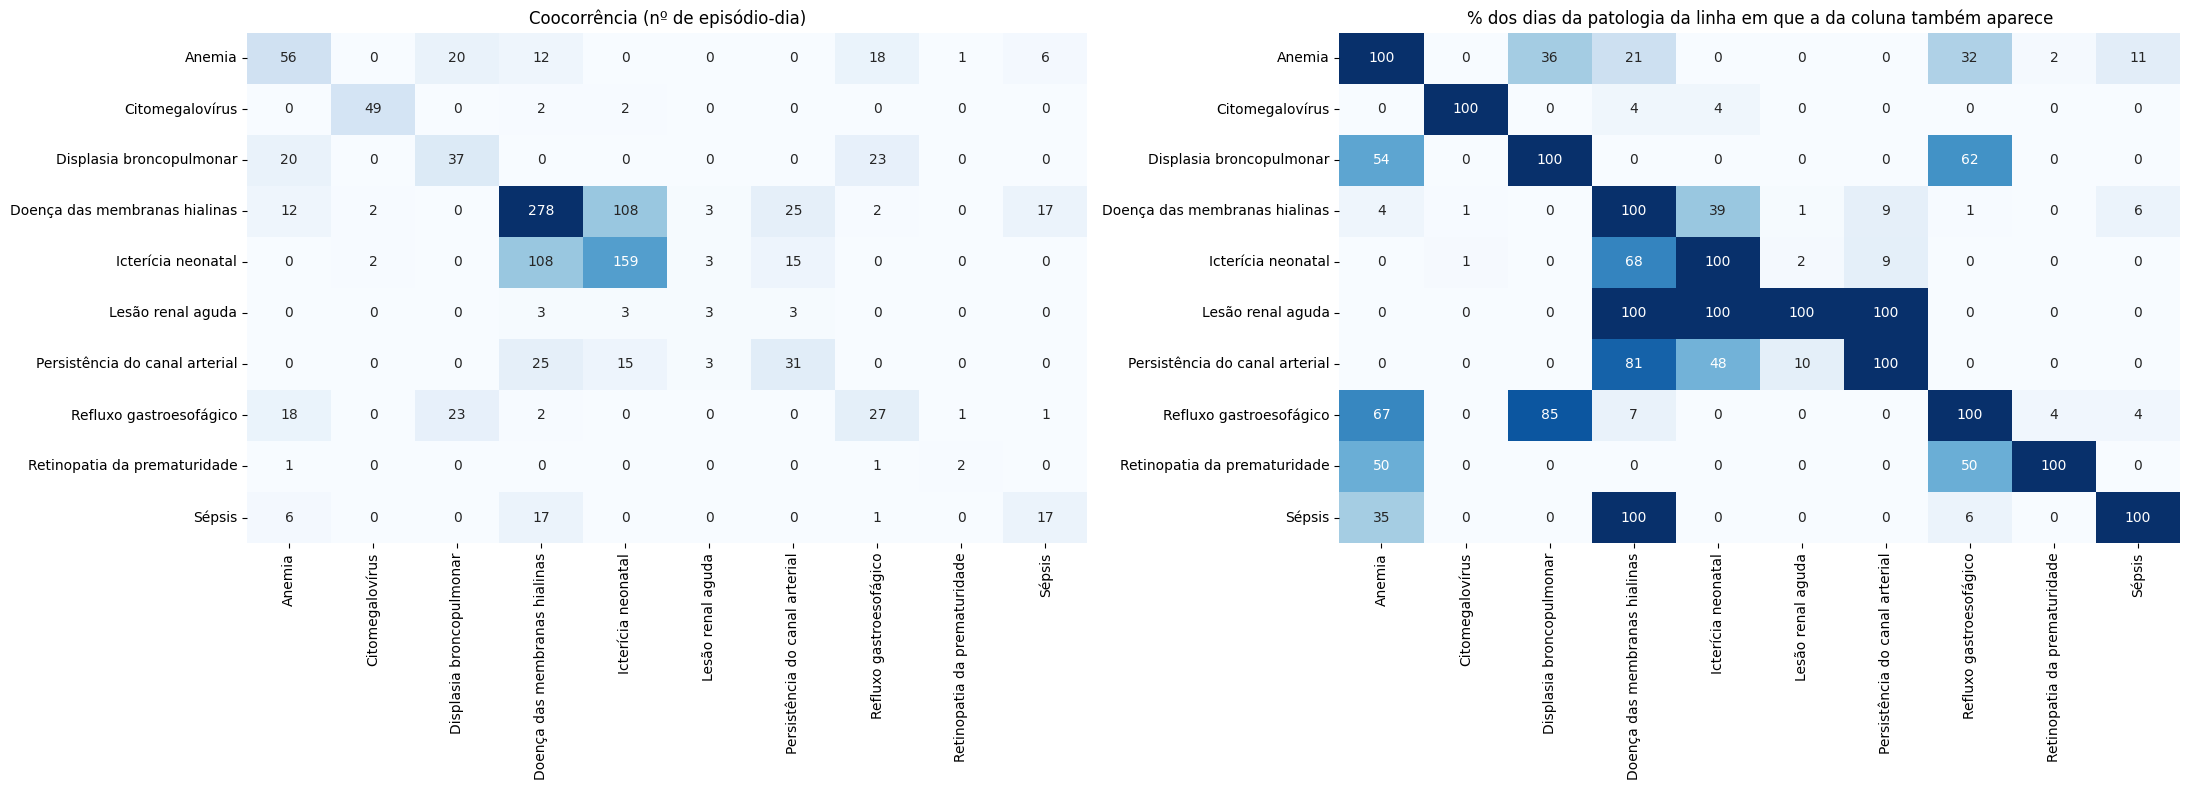

In [32]:
# =============================================================================
# 2.3.5 Coocorrência de patologias
# Para cada par de patologias, em quantos dias aparecem em simultâneo no
# mesmo episódio. Usa todos os dias com patologia (pat_dia, da 2.3.2),
# incluindo os dias sem sinais vitais.
# - Esquerda: nº de dias (a diagonal é o total de dias de cada patologia)
# - Direita: % dos dias da patologia da LINHA em que a da COLUNA também aparece
# Responde à pergunta de negócio: "que patologias tendem a coexistir?"
# =============================================================================
M = pat_dia[PATOLOGIAS]
coocorrencia = M.T @ M
percentagem = coocorrencia.div(np.diag(coocorrencia), axis=0).mul(100)

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
sns.heatmap(coocorrencia, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Coocorrência (nº de episódio-dia)")
sns.heatmap(percentagem, annot=True, fmt=".0f", cmap="Blues", cbar=False, vmin=0, vmax=100, ax=axes[1])
axes[1].set_title("% dos dias da patologia da linha em que a da coluna também aparece")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Dias com sinais vitais por patologia:


,nº de dias
Doença das membranas hialinas,232
Icterícia neonatal,115
Anemia,43
Displasia broncopulmonar,36
Citomegalovírus,32
Persistência do canal arterial,30
Refluxo gastroesofágico,23
Sépsis,11
Lesão renal aguda,2
Retinopatia da prematuridade,0


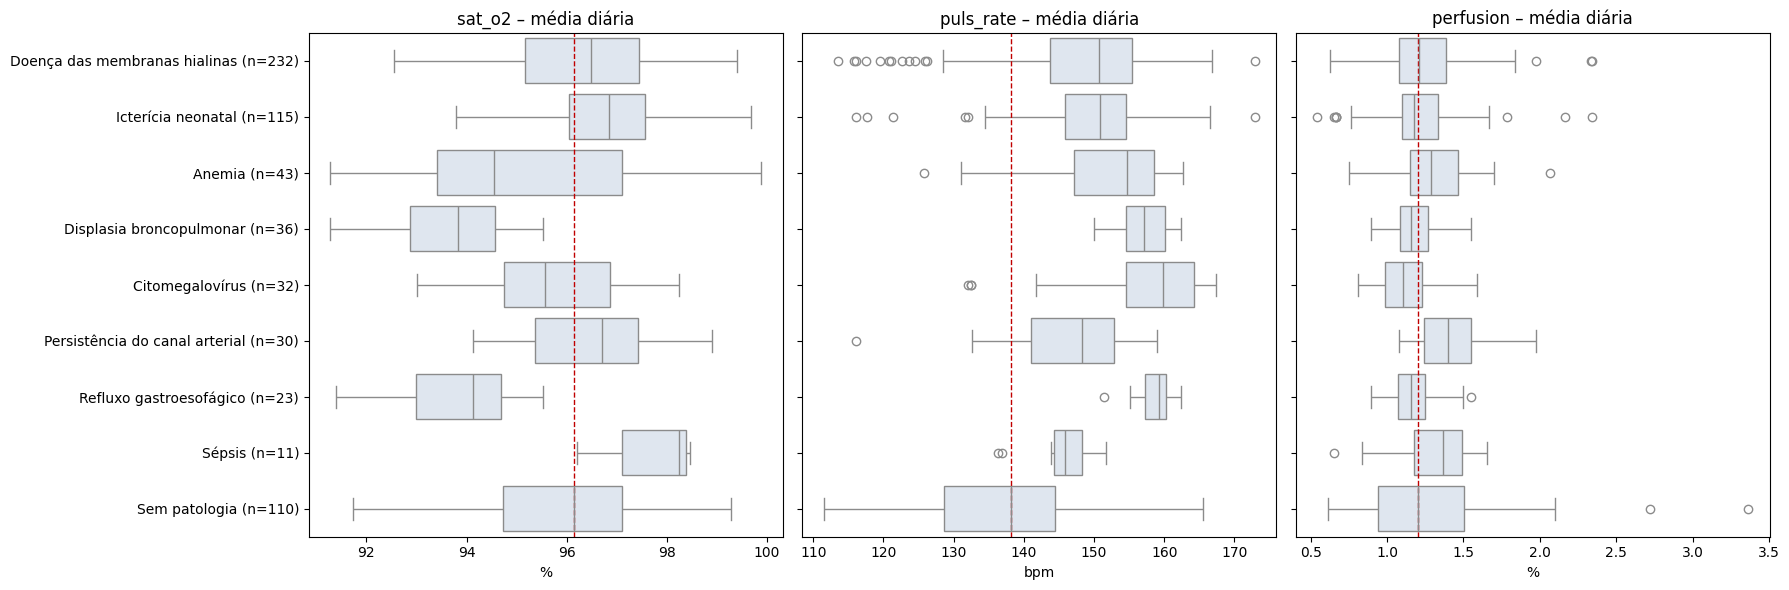

Mediana da média diária por grupo:


,sat_o2_mean,puls_rate_mean,perfusion_mean
grupo,,,
Anemia (n=43),94.55,154.72,1.29
Citomegalovírus (n=32),95.56,159.85,1.10
Displasia broncopulmonar (n=36),93.82,157.14,1.16
Doença das membranas hialinas (n=232),96.48,150.67,1.21
Icterícia neonatal (n=115),96.85,150.82,1.18
Persistência do canal arterial (n=30),96.70,148.28,1.40
Refluxo gastroesofágico (n=23),94.12,159.27,1.16
Sem patologia (n=110),96.14,138.21,1.20
Sépsis (n=11),98.24,145.84,1.36


In [33]:
# =============================================================================
# 2.3.6 Sinais vitais por patologia (DM1)
# Compara a média diária de cada sinal vital nos dias com cada patologia e
# nos dias sem nenhuma patologia registada (grupo de referência).
# Usa a ep_dia (só dias com sinais vitais).
# Só entram patologias com pelo menos 10 dias, para a comparação ter sentido;
# o nº de dias (n) aparece no nome de cada grupo.
# Nota: um dia com 2 patologias entra nas 2 caixas.
# =============================================================================
contagem = ep_dia[PATOLOGIAS].sum().sort_values(ascending=False)
print("Dias com sinais vitais por patologia:")
display(contagem.to_frame("nº de dias"))

FREQUENTES = contagem[contagem >= 10].index.tolist()
COLS = [f"{v}_mean" for v in VITAIS]

partes = [ep_dia.loc[ep_dia[p] == 1, COLS].assign(grupo=f"{p} (n={contagem[p]})") for p in FREQUENTES]
sem = ep_dia.loc[ep_dia["n_patologias"] == 0, COLS]
partes.append(sem.assign(grupo=f"Sem patologia (n={len(sem)})"))
por_patologia = pd.concat(partes)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for i, v in enumerate(VITAIS):
    sns.boxplot(data=por_patologia, x=f"{v}_mean", y="grupo", ax=axes[i], color="#DCE6F2")
    mediana_ref = sem[f"{v}_mean"].median()
    axes[i].axvline(mediana_ref, color="#C00000", ls="--", lw=1)   # mediana dos dias sem patologia
    axes[i].set_title(f"{v} – média diária")
    axes[i].set_xlabel(unidades[v])
    axes[i].set_ylabel("")
plt.tight_layout()
plt.show()

print("Mediana da média diária por grupo:")
display(por_patologia.groupby("grupo")[COLS].median().round(2))

Doença das membranas hialinas: 15 episódios com sinais vitais antes do aparecimento
Icterícia neonatal: 20 episódios com sinais vitais antes do aparecimento
Anemia: 6 episódios com sinais vitais antes do aparecimento
Displasia broncopulmonar: 1 episódios com sinais vitais antes do aparecimento
Citomegalovírus: 4 episódios com sinais vitais antes do aparecimento
Persistência do canal arterial: 3 episódios com sinais vitais antes do aparecimento
Refluxo gastroesofágico: 1 episódios com sinais vitais antes do aparecimento
Sépsis: 3 episódios com sinais vitais antes do aparecimento


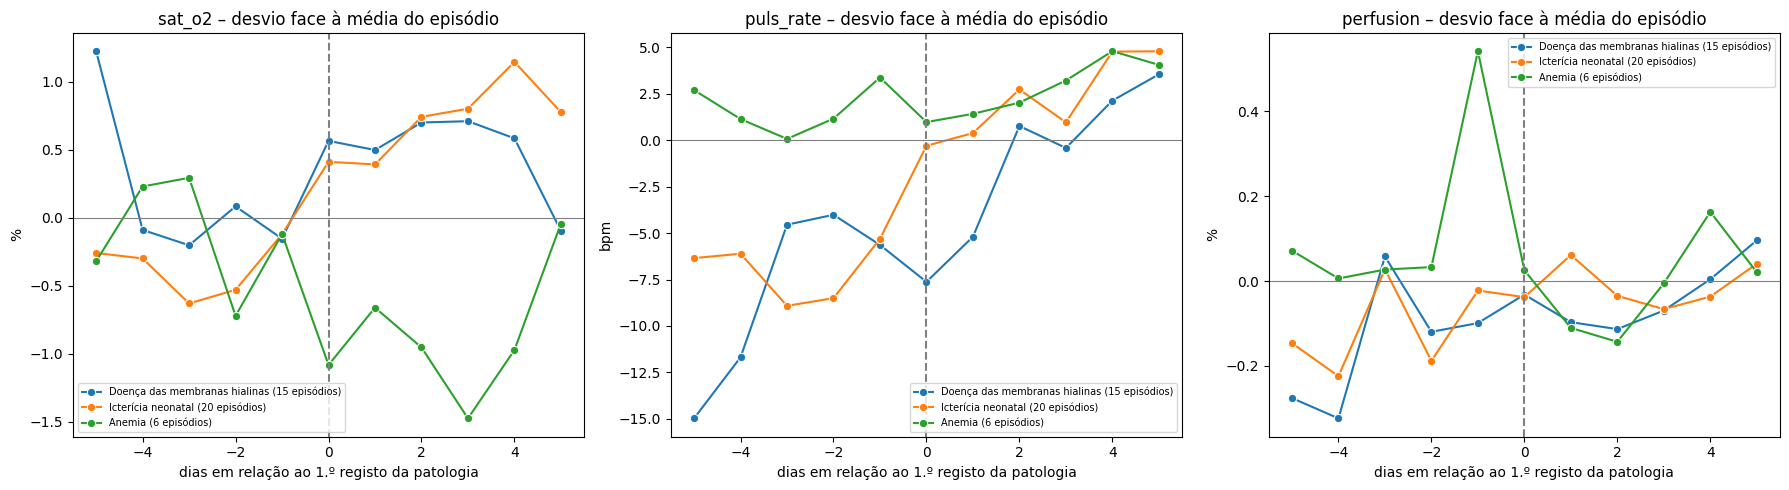

In [34]:
# =============================================================================
# 2.3.7 Evolução dos sinais vitais antes do aparecimento de uma patologia (DM1)
# Para cada episódio e patologia, o "dia 0" é o primeiro dia em que a
# patologia é registada (em qualquer dia, com ou sem sinais vitais).
# Mede-se a média diária dos sinais vitais entre 5 dias antes e 5 dias
# depois, em desvio face à média do próprio episódio (retira as diferenças
# entre bebés). Só entram episódios com sinais vitais antes do dia 0, e só
# patologias com pelo menos 5 desses episódios.
# Usa COLS e FREQUENTES da 2.3.6.
# Responde à pergunta: "há padrões nos sinais vitais que antecedem uma patologia?"
# =============================================================================
desvio = ep_dia[COLS] - ep_dia.groupby("episodio")[COLS].transform("mean")
desvio[["episodio", "data_dt"]] = ep_dia[["episodio", "data_dt"]]

linhas = []
for p in FREQUENTES:
    inicio_p = pat_exp[pat_exp["patologia"] == p].groupby("episodio")["data_dt"].min()
    inicio_p = inicio_p[inicio_p > ep.loc[inicio_p.index, "inicio"]]
    print(f"{p}: {len(inicio_p)} episódios com sinais vitais antes do aparecimento")
    if len(inicio_p) < 5:
        continue
    d = desvio[desvio["episodio"].isin(inicio_p.index)].copy()
    d["dia_rel"] = (d["data_dt"] - d["episodio"].map(inicio_p)).dt.days
    d = d[d["dia_rel"].between(-5, 5)]
    linhas.append(d.assign(patologia=f"{p} ({len(inicio_p)} episódios)"))

evolucao = pd.concat(linhas)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, v in enumerate(VITAIS):
    sns.lineplot(data=evolucao, x="dia_rel", y=f"{v}_mean", hue="patologia",
                 ax=axes[i], errorbar=None, marker="o")
    axes[i].axvline(0, color="grey", ls="--")
    axes[i].axhline(0, color="grey", lw=0.8)
    axes[i].set_title(f"{v} – desvio face à média do episódio")
    axes[i].set_xlabel("dias em relação ao 1.º registo da patologia")
    axes[i].set_ylabel(unidades[v])
    axes[i].legend(fontsize=7)
plt.tight_layout()
plt.show()

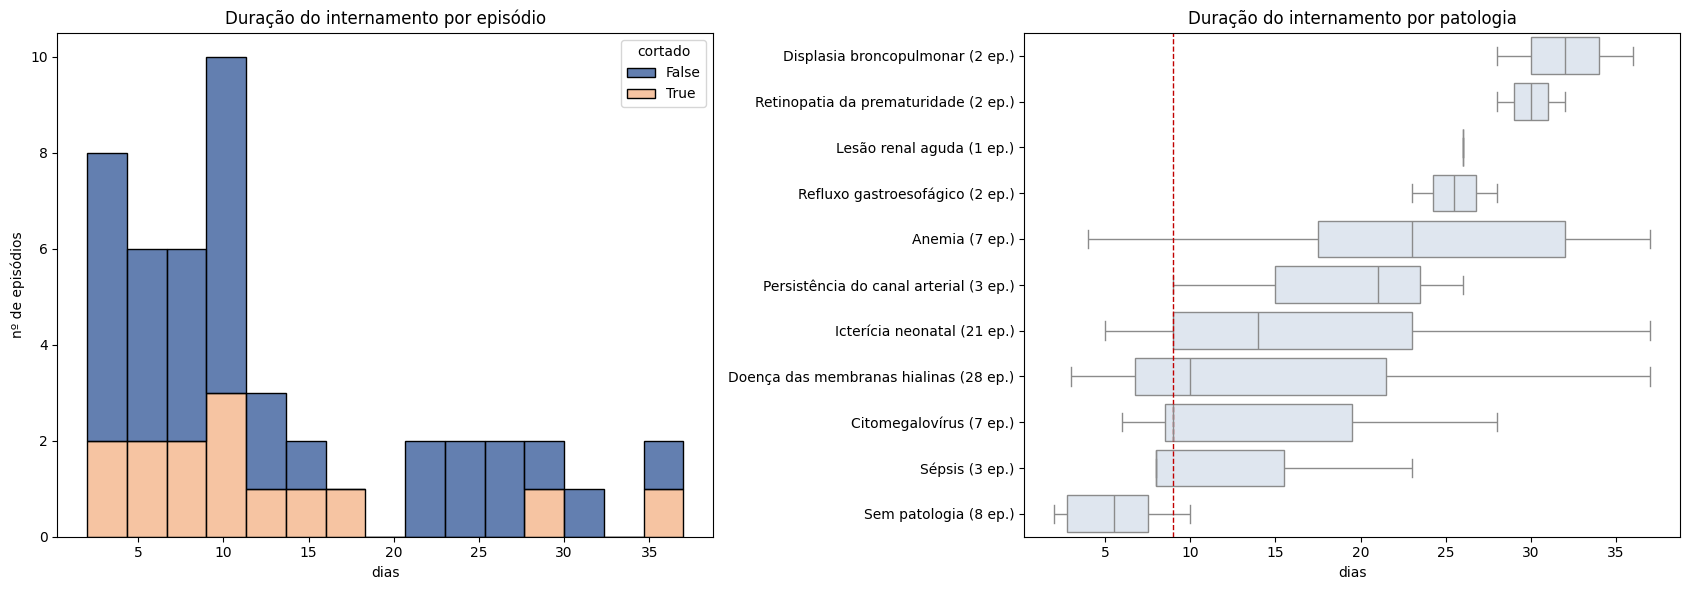

Mediana da duração por grupo:


,count,median
grupo,,
Displasia broncopulmonar (2 ep.),2,32.0
Retinopatia da prematuridade (2 ep.),2,30.0
Lesão renal aguda (1 ep.),1,26.0
Refluxo gastroesofágico (2 ep.),2,25.5
Anemia (7 ep.),7,23.0
Persistência do canal arterial (3 ep.),3,21.0
Icterícia neonatal (21 ep.),21,14.0
Doença das membranas hialinas (28 ep.),28,10.0
Citomegalovírus (7 ep.),7,9.0


Correlação de Spearman com a duração do internamento:


,rho
n_patologias_distintas,0.63
sat_o2,-0.07
puls_rate,0.55
perfusion,0.17


In [35]:
# =============================================================================
# 2.3.8 Duração do internamento (DM2)
# Usa a tabela ep (47 episódios) e a duracao_total (ambas as tabelas).
# Esquerda: distribuição da duração, distinguindo os episódios cortados.
# Direita: duração dos episódios que tiveram cada patologia em algum dia;
#          a linha vermelha é a mediana de todos os episódios.
# No fim: correlação de Spearman da duração com outras variáveis do episódio.
# Responde à pergunta: "que patologias estão associadas a internamentos
# mais longos?"
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Distribuição da duração (cortados a laranja)
sns.histplot(data=ep, x="duracao_total", hue="cortado", bins=15, multiple="stack",
             palette={False: "#2F5496", True: "#F4B183"}, ax=axes[0])
axes[0].set_title("Duração do internamento por episódio")
axes[0].set_xlabel("dias")
axes[0].set_ylabel("nº de episódios")

# Duração por patologia
n_ep = ep[PATOLOGIAS].sum()
partes = [ep.loc[ep[p] == 1, ["duracao_total"]].assign(grupo=f"{p} ({n_ep[p]} ep.)")
          for p in PATOLOGIAS if n_ep[p] > 0]
sem = ep.loc[ep["n_patologias_distintas"] == 0, ["duracao_total"]]
partes.append(sem.assign(grupo=f"Sem patologia ({len(sem)} ep.)"))
dur = pd.concat(partes)

ordem = dur.groupby("grupo")["duracao_total"].median().sort_values(ascending=False).index
sns.boxplot(data=dur, x="duracao_total", y="grupo", order=ordem, color="#DCE6F2", ax=axes[1])
axes[1].axvline(ep["duracao_total"].median(), color="#C00000", ls="--", lw=1)
axes[1].set_title("Duração do internamento por patologia")
axes[1].set_xlabel("dias")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

print("Mediana da duração por grupo:")
display(dur.groupby("grupo")["duracao_total"].agg(["count", "median"]).sort_values("median", ascending=False))

print("Correlação de Spearman com a duração do internamento:")
display(ep[["duracao_total", "n_patologias_distintas", "sat_o2", "puls_rate", "perfusion"]]
        .corr(method="spearman")["duracao_total"].drop("duracao_total").round(2).to_frame("rho"))

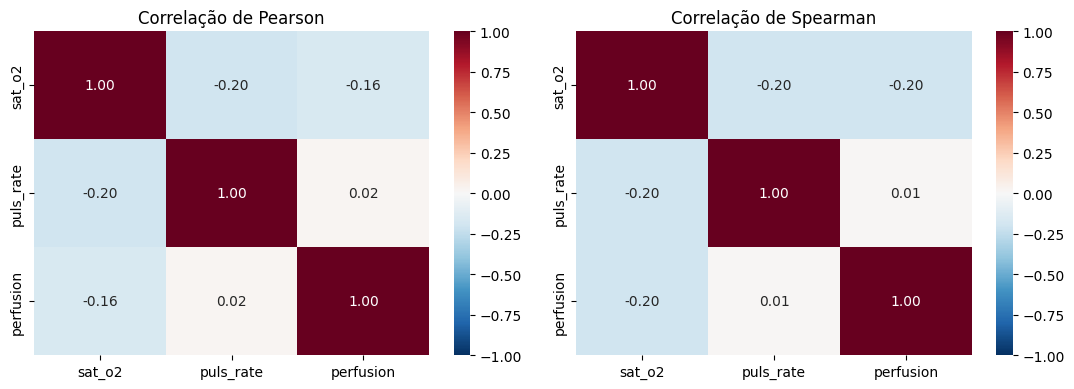

In [36]:
# =============================================================================
# 2.3.9 Correlação entre os sinais vitais
# Usa os registos horários (sv_exp), já sem valores impossíveis.
# - Pearson: mede relações lineares (em linha reta)
# - Spearman: mede relações monótonas (sobem/descem juntas, mesmo que não
#   em linha reta) e é mais robusta a valores extremos
# Valores perto de ±1 indicam redundância; perto de 0, informação independente.
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, metodo in enumerate(["pearson", "spearman"]):
    sns.heatmap(sv_exp[VITAIS].corr(method=metodo), annot=True, fmt=".2f",
                cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[i])
    axes[i].set_title(f"Correlação de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

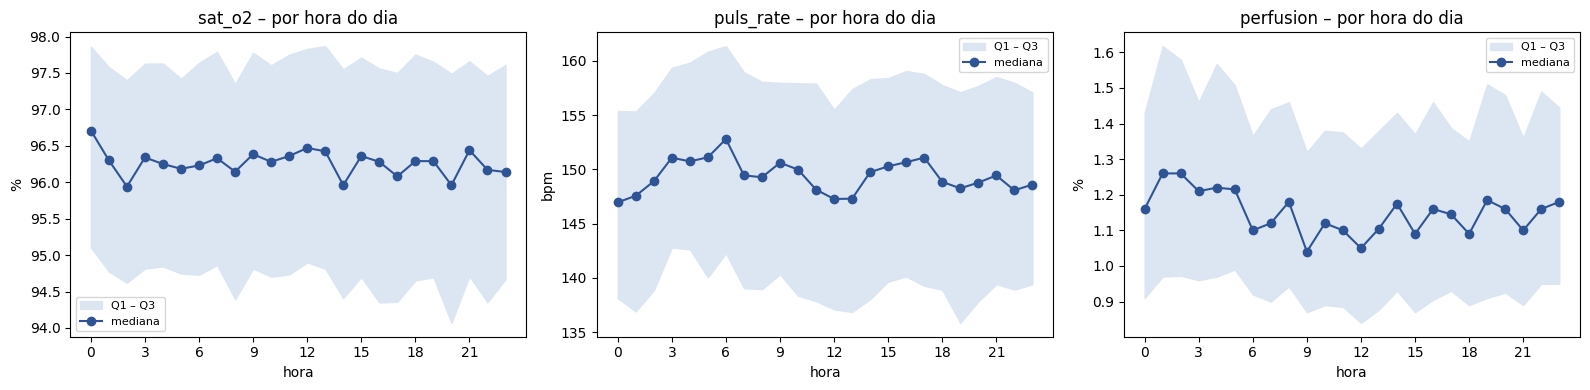

In [37]:
# =============================================================================
# 2.3.10 Padrão ao longo do dia
# Mediana de cada sinal vital em cada hora do dia (0 a 23), com todos os
# registos horários. Mostra se há variação diária (ex.: noite vs. dia).
# A sombra mostra o intervalo entre Q1 e Q3 em cada hora, para se perceber
# se as diferenças entre horas são grandes face à variação normal.
# =============================================================================
por_hora = sv_exp.groupby("hora")[VITAIS].quantile([0.25, 0.5, 0.75]).unstack()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, v in enumerate(VITAIS):
    axes[i].fill_between(por_hora.index, por_hora[(v, 0.25)], por_hora[(v, 0.75)],
                         color="#DCE6F2", label="Q1 – Q3")
    axes[i].plot(por_hora.index, por_hora[(v, 0.5)], marker="o", color="#2F5496", label="mediana")
    axes[i].set_title(f"{v} – por hora do dia")
    axes[i].set_xlabel("hora")
    axes[i].set_ylabel(unidades[v])
    axes[i].set_xticks(range(0, 24, 3))
    axes[i].legend(fontsize=8)
plt.tight_layout()
plt.show()

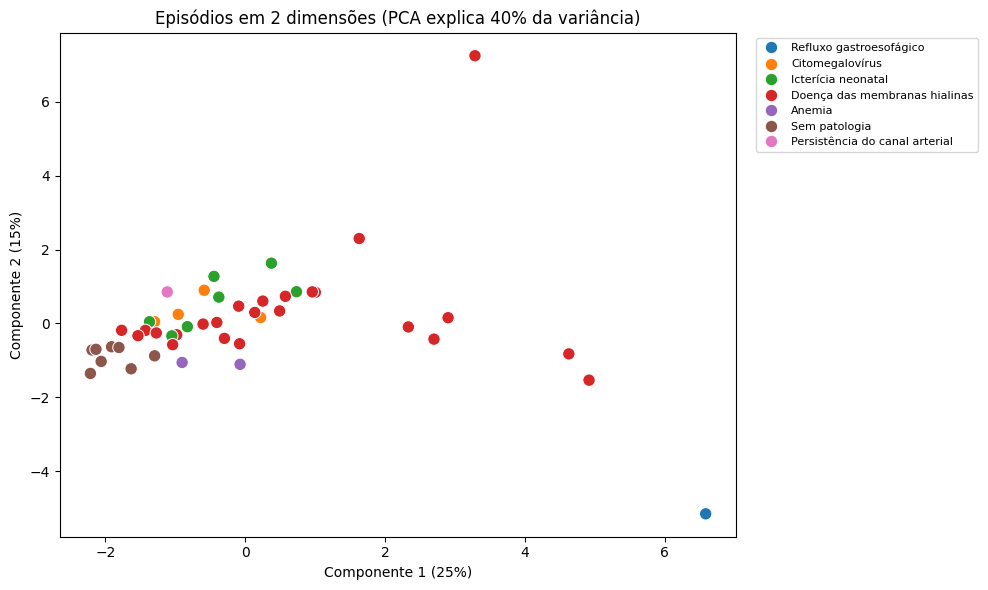

,Componente 1,Componente 2
sat_o2,-0.05,0.23
perfusion,-0.03,0.09
Citomegalovírus,0.01,0.30
Persistência do canal arterial,0.09,0.39
Sépsis,0.10,-0.07
Lesão renal aguda,0.13,0.46
Doença das membranas hialinas,0.19,0.23
Icterícia neonatal,0.26,0.28
Retinopatia da prematuridade,0.26,-0.26
puls_rate,0.29,0.06


In [40]:
# =============================================================================
# 2.3.11 Estrutura dos episódios (DM3)
# Usa a tabela ep (47 episódios). Reduz as características de cada episódio
# a 2 dimensões com PCA para ver se surgem grupos naturais.
# As variáveis são padronizadas antes (média 0, desvio 1), para que nenhuma
# pese mais só por estar numa escala maior (ex.: duração em dias vs. perfusão).
# A cor de cada ponto é a patologia registada em mais episódio-dia nesse
# episódio. Requer scikit-learn (pip install scikit-learn).
# =============================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

CARACT = ["sat_o2", "puls_rate", "perfusion", "duracao_total", "n_patologias_distintas"] + PATOLOGIAS
X = StandardScaler().fit_transform(ep[CARACT].fillna(ep[CARACT].median()))

pca = PCA(n_components=2)
coords = pca.fit_transform(X)

# Cor: patologia com mais episódio-dia em cada episódio (todos os registos)
ep_dia_pat = pat_dia.groupby(level="episodio")[PATOLOGIAS].sum()
principal = (ep_dia_pat.reindex(ep.index, fill_value=0).idxmax(axis=1)
             .where(ep["n_patologias_distintas"] > 0, "Sem patologia"))

plt.figure(figsize=(10, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=principal, s=80)
plt.title(f"Episódios em 2 dimensões (PCA explica {pca.explained_variance_ratio_.sum():.0%} da variância)")
plt.xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Que variáveis mais pesam em cada componente
pesos = pd.DataFrame(pca.components_.T, index=CARACT, columns=["Componente 1", "Componente 2"])
display(pesos.round(2).sort_values("Componente 1"))